# แหล่งข้อมูลที่ใช้

- ข้อมูลที่ใช้ : ข้อมูลการเดินทางของรถแท็กซี่ประเภท Yellow, Green, For-Hire Vehicle(fhv)และ High Volume For-Hire Vehicle (fhvhv) ตั้งแต่ช่วงเวลาเดือน **มกราคม 2024 - มิถุนายน 2024**

- แหล่งที่มา : จากเว็บ [NYC Taxi and Limousine Commission](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) ในรูปแบบไฟล์ Parquet




# วิธีการวัดและเปรียบเทียบคำว่า "Most Used"
**Metric ที่ใช้:** จำนวนการเดินทางที่เกิดขึ้นจริง (Number of valid trip records)

**เหตุผลที่เลือกใช้:** การวัดความนิยมโดยใช้จำนวนแถวข้อมูลดิบอาจมีความคลาดเคลื่อนจากข้อมูลขยะหรือข้อผิดพลาดของระบบ และข้อมูลแท็กซี่แต่ละประเภทมีรูปแบบการคิดเงินหรือระยะทางที่ต่างกัน ดังนั้น การนับ "จำนวนการเดินทางที่ผ่านการคัดกรองเงื่อนไขแล้ว" จึงเป็นตัวชี้วัดที่สะท้อนปริมาณการใช้งานจริงได้ดีที่สุด

**วิธีการวัดผล:** จะทำการนับจำนวนข้อมูลเฉพาะแถวที่ผ่านเกณฑ์การทำความสะอาด ได้แก่ การมีข้อมูลเวลาขึ้น-ลงรถครบถ้วน, ระยะเวลาการเดินทางไม่ติดลบ และเกิดขึ้นในช่วงเวลาเป้าหมาย จากนั้นนำผลรวมที่ได้ของแต่ละประเภทมาเปรียบเทียบเพื่อหาอันดับหนึ่งที่มีจำนวนการเดินทางมากที่สุด

In [ ]:
METRIC = "Number of valid trip records"
print("Metric:", METRIC)

Metric: Number of valid trip records


# การเตรียมข้อมูล

- **การนำเข้าข้อมูล:** สร้างโฟลเดอร์เพื่อเก็บไฟล์ข้อมูลและทำการดึงข้อมูลไฟล์ Parquet ของแท็กซี่ทั้ง 4 ประเภท Yellow, Green, fhv และ fhvhv ในช่วง 6 เดือนแรกของปี 2024 โดยเขียนเงื่อนไขให้ตรวจสอบก่อนว่ามีไฟล์ในเครื่องแล้วหรือไม่ เพื่อป้องกันการดาวน์โหลดซ้ำซ้อน

In [ ]:
import os
import urllib.request

data_dir = '/content/cs341_m2_data'
os.makedirs(data_dir, exist_ok=True) #สร้างโฟลเดอร์โดยที่ exist_ok = true คือถ้ามีชื่อโฟลเดอร์นี้อยู่แล้วให้ข้ามไปเลยโดนไม่ต้องแจ้ง error

taxi_types = ['yellow', 'green', 'fhv', 'fhvhv']
months = ['01', '02', '03', '04', '05', '06']
downloaded_files = {}

print("--- เริ่มการนำเข้าข้อมูล ---")
total_expected_files = len(taxi_types) * len(months)
actual_valid_files = 0

for taxi in taxi_types:
    downloaded_files[taxi] = []

    for month in months:
        file_name = f"{taxi}_tripdata_2024-{month}.parquet"
        url = f"https://d37ci6vzurychx.cloudfront.net/trip-data/{file_name}"
        file_path = os.path.join(data_dir, file_name)

        try:
            # ตรวจสอบว่ามีไฟล์หรือยัง ถ้ายังให้ดาวน์โหลด
            if not os.path.exists(file_path):
                print(f"กำลังดาวน์โหลด: {file_name}...")
                urllib.request.urlretrieve(url, file_path)

            # ตรวจสอบความสมบูรณ์ของไฟล์ (ป้องกันโหลดมาเป็นไฟล์เปล่า)
            if os.path.getsize(file_path) > 0:
                print(f"พบไฟล์ {file_name} (สมบูรณ์)")
                downloaded_files[taxi].append(file_path)
                actual_valid_files += 1
            else:
                raise Exception("ไฟล์มีขนาด 0 Byte โหลดไม่สมบูรณ์")

        except Exception as e:
            print(f"ไม่พบไฟล์หรือเกิดข้อผิดพลาดกับ {file_name} ({e})")

print("--- นำเข้าข้อมูลเสร็จสิ้น ---")

#  ต้องครบ 24 ไฟล์ ถึงจะให้ไปต่อได้
if actual_valid_files != total_expected_files:
    raise Exception(f" ข้อมูลไม่ครบ ต้องการ {total_expected_files} ไฟล์ แต่มีไฟล์สมบูรณ์แค่ {actual_valid_files} ไฟล์ ระบบหยุดทำงานเพื่อป้องกันการประมวลผลสถิติผิดพลาด")
else:
    print("\n ข้อมูลดาวน์โหลดและตรวจสอบครบถ้วนทั้ง 24 ไฟล์ พร้อมประมวลผลต่อ!")

--- เริ่มการนำเข้าข้อมูล ---
พบไฟล์ yellow_tripdata_2024-01.parquet (สมบูรณ์)
พบไฟล์ yellow_tripdata_2024-02.parquet (สมบูรณ์)
พบไฟล์ yellow_tripdata_2024-03.parquet (สมบูรณ์)
พบไฟล์ yellow_tripdata_2024-04.parquet (สมบูรณ์)
พบไฟล์ yellow_tripdata_2024-05.parquet (สมบูรณ์)
พบไฟล์ yellow_tripdata_2024-06.parquet (สมบูรณ์)
พบไฟล์ green_tripdata_2024-01.parquet (สมบูรณ์)
พบไฟล์ green_tripdata_2024-02.parquet (สมบูรณ์)
พบไฟล์ green_tripdata_2024-03.parquet (สมบูรณ์)
พบไฟล์ green_tripdata_2024-04.parquet (สมบูรณ์)
พบไฟล์ green_tripdata_2024-05.parquet (สมบูรณ์)
พบไฟล์ green_tripdata_2024-06.parquet (สมบูรณ์)
พบไฟล์ fhv_tripdata_2024-01.parquet (สมบูรณ์)
พบไฟล์ fhv_tripdata_2024-02.parquet (สมบูรณ์)
พบไฟล์ fhv_tripdata_2024-03.parquet (สมบูรณ์)
พบไฟล์ fhv_tripdata_2024-04.parquet (สมบูรณ์)
พบไฟล์ fhv_tripdata_2024-05.parquet (สมบูรณ์)
พบไฟล์ fhv_tripdata_2024-06.parquet (สมบูรณ์)
พบไฟล์ fhvhv_tripdata_2024-01.parquet (สมบูรณ์)
พบไฟล์ fhvhv_tripdata_2024-02.parquet (สมบูรณ์)
พบไฟล์ fhvhv_trip

- **ตรวจสอบขนาดไฟล์:** ก่อนที่จะโหลดข้อมูลไปประมวลผล ทำการตรวจสอบขนาดไฟล์ ก่อนเพื่อประเมินปัญหาด้านปริมาณข้อมูล และป้องกันปัญหา RAM เต็ม

In [ ]:
print("--- ตรวจสอบขนาดไฟล์ก่อนประมวลผล ---")

for taxi, files in downloaded_files.items():
    print(f"\n ประเภท: {taxi.upper()}")
    total_size = 0

    for file_path in files:
        file_name = os.path.basename(file_path)
        # คำนวณขนาดไฟล์เป็น Megabytes (MB)
        file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
        total_size += file_size_mb

        print(f"  - {file_name}: {file_size_mb:.2f} MB")

    print(f"  รวมขนาดไฟล์ของ {taxi.upper()}: {total_size:.2f} MB")

--- ตรวจสอบขนาดไฟล์ก่อนประมวลผล ---

 ประเภท: YELLOW
  - yellow_tripdata_2024-01.parquet: 47.65 MB
  - yellow_tripdata_2024-02.parquet: 48.02 MB
  - yellow_tripdata_2024-03.parquet: 57.30 MB
  - yellow_tripdata_2024-04.parquet: 56.39 MB
  - yellow_tripdata_2024-05.parquet: 59.66 MB
  - yellow_tripdata_2024-06.parquet: 57.09 MB
  รวมขนาดไฟล์ของ YELLOW: 326.10 MB

 ประเภท: GREEN
  - green_tripdata_2024-01.parquet: 1.30 MB
  - green_tripdata_2024-02.parquet: 1.22 MB
  - green_tripdata_2024-03.parquet: 1.31 MB
  - green_tripdata_2024-04.parquet: 1.28 MB
  - green_tripdata_2024-05.parquet: 1.39 MB
  - green_tripdata_2024-06.parquet: 1.26 MB
  รวมขนาดไฟล์ของ GREEN: 7.77 MB

 ประเภท: FHV
  - fhv_tripdata_2024-01.parquet: 14.33 MB
  - fhv_tripdata_2024-02.parquet: 12.98 MB
  - fhv_tripdata_2024-03.parquet: 15.97 MB
  - fhv_tripdata_2024-04.parquet: 15.75 MB
  - fhv_tripdata_2024-05.parquet: 15.22 MB
  - fhv_tripdata_2024-06.parquet: 15.29 MB
  รวมขนาดไฟล์ของ FHV: 89.53 MB

 ประเภท: FHVHV
  - f

- **ตรวจสอบโครงสร้างข้อมูล:** ข้อมูลแท็กซี่แต่ละประเภทมาจากต่างระบบกัน จึงมีความหลากหลาย ก่อนที่จะเขียนโค้ดเพื่อทำความสะอาดข้อมูล ต้องตรวจสอบโครงสร้างคอลัมน์  ของแต่ละไฟล์ก่อน เนื่องจาก Valid ในที่นี้คือจำนวนการเดินทางที่เกิดขึ้นจริงเลยต้องหาเวลาจากคอลัมน์ที่เกียวกับ "เวลาขึ้น" และ "เวลาลงรถ" ใช้ชื่อว่าอะไรโดยใช้ DuckDB อ่าน Metadata ของไฟล์โดยไม่ต้องโหลดข้อมูลทั้งหมด

In [ ]:
import duckdb
import os

print("--- ตรวจสอบโครงสร้างคอลัมน์ ---")

for taxi, files in downloaded_files.items():
    if len(files) > 0:
        print(f"\n ประเภท: {taxi.upper()}")
        for file_path in files:
            file_name = os.path.basename(file_path)
            # ใช้ DuckDB DESCRIBE อ่าน Schema ของไฟล์ Parquete
            schema_query = f"DESCRIBE SELECT * FROM '{file_path}'"
            schema_df = duckdb.sql(schema_query).df() #ให้ DuckDB ประมวลผลและเก็บในรูปแบบ DuckDB Relation แล้วใช้ .df แปลงเป็น DataFrame

            # กรองดูเฉพาะคอลัมน์ที่มีคำว่า pickup หรือ dropoff เพื่อหาชื่อคอลัมน์เวลา
            #case=False มาจาก casesensitive คือ ไม่ต้องสนใจว่าตัวอักษรจะเป็นพิมพ์เล็กหรือพิมพ์ใหญ่ และ na=False ย่อมาจาก NaN (Not a Number) คือถ้าไปเจอค่าว่างให้เปลี่ยนแปลว่าไม่เจอ
            time_cols = schema_df[schema_df['column_name'].str.contains('pickup|dropoff', case=False, na=False)]['column_name'].tolist()

            print(f" - {file_name} \nคอลัมน์ที่เกี่ยวกับเวลา: {time_cols}")

--- ตรวจสอบโครงสร้างคอลัมน์ ---

 ประเภท: YELLOW
 - yellow_tripdata_2024-01.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']
 - yellow_tripdata_2024-02.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']
 - yellow_tripdata_2024-03.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']
 - yellow_tripdata_2024-04.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']
 - yellow_tripdata_2024-05.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']
 - yellow_tripdata_2024-06.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']

 ประเภท: GREEN
 - green_tripdata_2024-01.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['lpep_pickup_datetime', 'lpep_dropoff_datetime']
 - green_tripdata_2024-02.parquet 
คอลัมน์ที่เกี่ยวกับเวลา: ['lpep_pickup_datetime', 'lpep_dropoff_datetime']
 - green_tripdata_2024-03.parquet 
คอลัมน์ที่เกี่

จะสังเกตุเห็นได้ว่าคอลัมน์ pickup และ dropoff ของ YELLOW และ GREEN มีรูปแบบที่แตกต่างจาก FHV และ FHVHV เลยต้องทำการ normalize ข้อมูลให้มีรูปแบบเดียวกัน

- **การจัดการความหลากหลายของข้อมูล:** ในแง่ File Format ข้อมูลทั้ง 4 ประเภทถูกจัดเก็บเป็น Parquet เหมือนกันอยู่แล้วจึงไม่ต้องแปลง format ระหว่างกันสิ่งที่ต้องบูรณาการจริงๆ คือ Schema โดยเฉพาะชื่อคอลัมน์ pickup/dropoff ที่ต่างกันในแต่ละประเภทรถรถจึงต้องใช้เงื่อนไข `if-elif` ในการจับคู่ชื่อคอลัมน์ให้ถูกก่อนประมวลผล




- **การตรวจสอบและทำความสะอาด:** ใช้ DuckDB คิวรีข้อมูลจากไฟล์ Local โดยตรง เพื่อหลีกเลี่ยงปัญหา RAM เต็ม และทำความสะอาดโดยเก็บเฉพาะข้อมูลที่มีเวลาขึ้น-ลงรถครบถ้วน ,เวลาลงรถต้องไม่เกิดก่อนเวลาขึ้นรถ และต้องเป็นข้อมูลที่อยู่ในช่วงระหว่างเดือน มกราคม - มิถุนายน ปี 2024

In [ ]:
import duckdb
import pandas as pd
import os

print("--- เริ่มกระบวนการทำความสะอาดและบูรณาการข้อมูล ---")
results = {}
total_valid_clean_trips = 0
audit_data = [] # เพิ่มตัวแปร List ว่างๆ ไว้สำหรับเก็บข้อมูลไปทำตาราง

# วนลูปตามรายชื่อไฟล์ที่ดาวน์โหลดมาแล้วใน Cell แรก
for taxi, files in downloaded_files.items():
    if not files:
        continue

    print(f"\n ประมวลผลรถประเภท: {taxi.upper()}")
    total_clean_trips = 0

    for file_path in files:
        # ดึงตัวเลขเดือนมาใช้แสดงผล
        month = file_path.split('-')[-1].replace('.parquet', '')

        try:
            # Schema Alignment
            if taxi == 'yellow':
                pickup_col, dropoff_col = 'tpep_pickup_datetime', 'tpep_dropoff_datetime'
            elif taxi == 'green':
                pickup_col, dropoff_col = 'lpep_pickup_datetime', 'lpep_dropoff_datetime'
            elif taxi == 'fhv':
                pickup_col, dropoff_col = 'pickup_datetime', 'dropOff_datetime'
            else: # fhvhv
                pickup_col, dropoff_col = 'pickup_datetime', 'dropoff_datetime'

            # Integration & Cleaning Query นับข้อมูลดิบและคลีน
            query = f"""
                SELECT
                    '{taxi.upper()}' AS taxi_type,
                    '{month}' AS month,
                    COUNT(*) AS raw_records,
                    COUNT(CASE WHEN {pickup_col} IS NOT NULL
                                AND {dropoff_col} IS NOT NULL
                                AND {dropoff_col} >= {pickup_col}
                                AND {pickup_col} >= '2024-01-01'
                                AND {pickup_col} < '2024-07-01'
                          THEN 1 END) AS valid_records
                FROM '{file_path}'
            """

            result = duckdb.sql(query).fetchone() #.fetchone() คือ fetch ดึงข้อมูลทีละแถว

            raw_count = result[2]
            clean_count = result[3]
            removed = raw_count - clean_count

            print(f"  - เดือน {month}: ดิบ {raw_count:,} -> คลีน {clean_count:,} (ตัดทิ้ง {removed:,})")

            total_clean_trips += clean_count
            total_valid_clean_trips += clean_count

            # เก็บข้อมูลเข้า List ไว้ทำตาราง Audit
            audit_data.append({
                'taxi_type': result[0],
                'month': result[1],
                'raw_records': raw_count,
                'valid_records': clean_count,
                'invalid_records': removed
            })

        except Exception as e:
            print(f"  - เดือน {month}: เกิดข้อผิดพลาดในการประมวลผล ({e})")

    # เก็บผลรวมของแต่ละประเภท
    results[taxi] = total_clean_trips
    print(f" รวม Valid Trips ของ {taxi.upper()}: {total_clean_trips:,} เที่ยว")

#  สร้างตาราง Audit Table
audit_df = pd.DataFrame(audit_data)
print("\n[ตาราง Audit Table ]")
display(audit_df)

print(f" \nจำนวนเดินทาง Valid Trips ทั้งหมด: {total_valid_clean_trips:,} เที่ยว")
print("\n--- ประมวลผลเสร็จสิ้น ---")

--- เริ่มกระบวนการทำความสะอาดและบูรณาการข้อมูล ---

 ประมวลผลรถประเภท: YELLOW
  - เดือน 01: ดิบ 2,964,624 -> คลีน 2,964,553 (ตัดทิ้ง 71)
  - เดือน 02: ดิบ 3,007,526 -> คลีน 3,007,517 (ตัดทิ้ง 9)
  - เดือน 03: ดิบ 3,582,628 -> คลีน 3,582,509 (ตัดทิ้ง 119)
  - เดือน 04: ดิบ 3,514,289 -> คลีน 3,514,215 (ตัดทิ้ง 74)
  - เดือน 05: ดิบ 3,723,833 -> คลีน 3,723,784 (ตัดทิ้ง 49)
  - เดือน 06: ดิบ 3,539,193 -> คลีน 3,539,176 (ตัดทิ้ง 17)
 รวม Valid Trips ของ YELLOW: 20,331,754 เที่ยว

 ประมวลผลรถประเภท: GREEN
  - เดือน 01: ดิบ 56,551 -> คลีน 56,549 (ตัดทิ้ง 2)
  - เดือน 02: ดิบ 53,577 -> คลีน 53,577 (ตัดทิ้ง 0)
  - เดือน 03: ดิบ 57,457 -> คลีน 57,455 (ตัดทิ้ง 2)
  - เดือน 04: ดิบ 56,471 -> คลีน 56,471 (ตัดทิ้ง 0)
  - เดือน 05: ดิบ 61,003 -> คลีน 61,001 (ตัดทิ้ง 2)
  - เดือน 06: ดิบ 54,748 -> คลีน 54,748 (ตัดทิ้ง 0)
 รวม Valid Trips ของ GREEN: 339,801 เที่ยว

 ประมวลผลรถประเภท: FHV
  - เดือน 01: ดิบ 1,290,116 -> คลีน 1,290,116 (ตัดทิ้ง 0)
  - เดือน 02: ดิบ 1,176,093 -> คลีน 1,176,093 (ตัดทิ้ง 0)


,taxi_type,month,raw_records,valid_records,invalid_records
0,YELLOW,01,2964624,2964553,71
1,YELLOW,02,3007526,3007517,9
2,YELLOW,03,3582628,3582509,119
3,YELLOW,04,3514289,3514215,74
4,YELLOW,05,3723833,3723784,49
5,YELLOW,06,3539193,3539176,17
6,GREEN,01,56551,56549,2
7,GREEN,02,53577,53577,0
8,GREEN,03,57457,57455,2
9,GREEN,04,56471,56471,0


 
จำนวนเดินทาง Valid Trips ทั้งหมด: 149,655,451 เที่ยว

--- ประมวลผลเสร็จสิ้น ---


# ผลลัพธ์ที่ได้และความหมาย
-  **ผลลัพธ์ที่ได้:** จากการเปรียบเทียบข้อมูลครึ่งปีแรกของปี 2024 พบว่าแท็กซี่ประเภท **FHVHV** เป็นประเภทที่ถูกใช้งานมากที่สุด จากทั้ง 4 ประเภท
-  **ความหมาย:** แสดงให้เห็นถึงการเรียกรถของผู้โดยสารในนิวยอร์กนั้นนิยมใช้เป็นการใช้แอปพลิเคชันเรียกรถ (FHVHV) เช่น Uber เป็นหลัก แทนที่จะยืนโบกแท็กซี่แบบดั้งเดิม (Yellow/Green) หรือการโทรเรียกศูนย์รถ (FHV)โดยตัวเลขที่นำมาเปรียบเทียบนี้ ไม่ใช่แค่การนับจำนวนบรรทัดทั่วไป แต่เป็นตัวเลขที่ผ่านกระบวนการทำความสะอาด โดยตัดข้อมูลที่ผิดพลาดทางตรรกะเวลาออกไปแล้ว เช่น ลงรถก่อนขึ้นรถ หรือข้อมูลที่ไม่ได้อยู่ในช่วงเวลาที่สนใจ ทำให้ผลลัพธ์นี้สะท้อน "จำนวนการเดินทางที่เกิดขึ้นและสำเร็จจริง" มีความน่าเชื่อถือ และสามารถอธิบายที่มาที่ไปเพื่อนำไปใช้ต่อได้

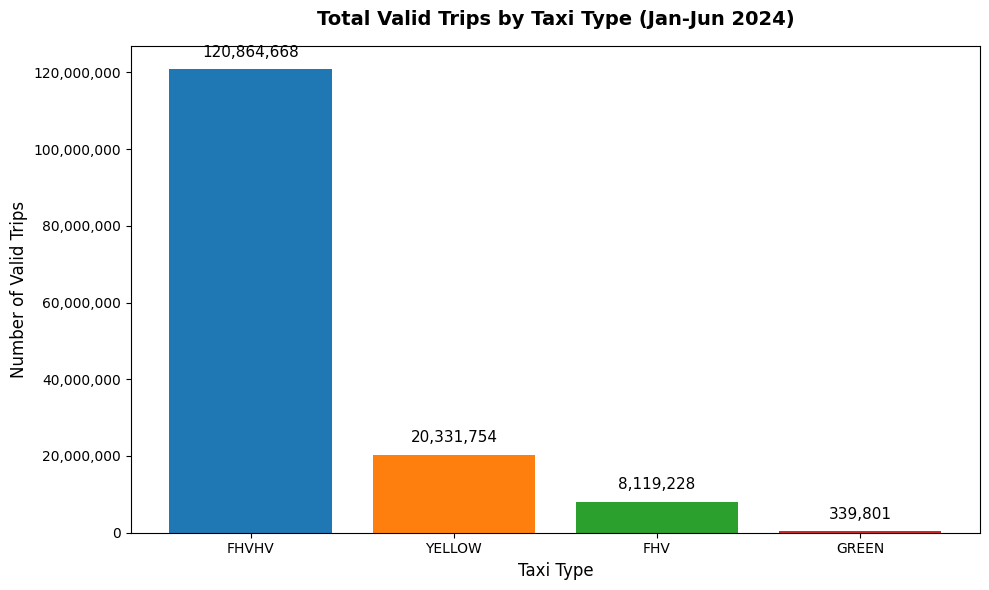

In [ ]:
import matplotlib.pyplot as plt

# จัดเรียงข้อมูลจากมากไปน้อยเพื่อกราฟที่ดูง่ายขึ้น
#results.items() แปลงข้อมูลให้เป็นกลุ่มข้อมูลคู่ เช่น ('yellow', 20331793) เพื่อให้วนลูปเรียงลำดับ sorted(key=lambda item: item[1])สั่งจัดเรียงข้อมูลโดย key คือ item[1] และ reverse=Trueเรียงจากค่ามากไปหาค่าน้อยและแปลงค่าจากlist หลังเรียง ให้เป็น tuple ด้วย dict
sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))

taxis = [taxi.upper() for taxi in sorted_results.keys()]
trips = list(sorted_results.values())

# ตั้งค่าขนาดกราฟ
plt.figure(figsize=(10, 6))

# สร้างกราฟแท่ง และกำหนดสี
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = plt.bar(taxis, trips, color=colors)

# ปรับแต่งหัวข้อและแกน
plt.title('Total Valid Trips by Taxi Type (Jan-Jun 2024)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Taxi Type', fontsize=12)
plt.ylabel('Number of Valid Trips', fontsize=12)

# ใส่ตัวเลขกำกับไว้บนหัวกราฟแต่ละแท่ง
for bar in bars:
    yval = bar.get_height()
    # จัด Format ใส่ลูกน้ำให้ตัวเลขดูง่าย
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max(trips) * 0.02),
             f'{int(yval):,}', ha='center', va='bottom', fontsize=11)

# ปรับแกน Y ให้แสดงตัวเลขแบบมีลูกน้ำแทนตัวเลขวิทยาศาสตร์ (e)
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# แสดงกราฟ
plt.tight_layout()
plt.show()

# Data Lifecycle
กระบวนการใน Notebook นี้สอดคล้องกับ Data Lifecycle ดังนี้:
1. **Generation / Source:** เกิดจากการที่ผู้โดยสารเรียกใช้บริการ และระบบมิเตอร์ของแท็กซี่ หรือแอปพลิเคชัน เช่น Uber ทำการบันทึกเวลาขึ้น-ลงรถ และระยะทางะแล้วถูกเก็บโดยระบบของ NYC TLC
2. **Storage:** NYC TLC นำข้อมูลมาแปลงให้อยู่ในรูปแบบไฟล์ Parquet แบบแบ่งรายเดือน และเผยแพร่ไฟล์ผ่าน Url ของ Amazon CloudFront
3. **Ingestion:** ใช้ไลบรารี `urllib` ดาวน์โหลดไฟล์มาจัดเก็บใน Local Directory โดยมีการเช็คเงื่อนไขตรวจสอบเพื่อไม่ให้โหลดซ้ำ
4. **Transformation (Cleaning & Integration):**
   - *Inspection:* ตรวจสอบขนาดไฟล์และโครงสร้างคอลัมน์ (Schema) รวมถึงตรวจหา Outlier ด้านเวลา
   - *Integration:* ทำ Schema Alignment ปรับชื่อคอลัมน์ `pickup` และ `dropoff` ของแท็กซี่ทั้ง 4 ประเภทให้ตรงกัน
   - *Cleaning:* ใช้ DuckDB คิวรีเพื่อกรองข้อมูลที่เวลาไม่สมบูรณ์ ข้อมูลที่เวลาติดลบ และข้อมูลที่อยู่นอกขอบเขตครึ่งปีแรกของ 2024
5. **Analytics:** นำจำนวนทริปที่เกิดขึ้นจริง (Valid Trips) มาเปรียบเทียบเพื่อหา "Most Used" และใช้ไลบรารี `matplotlib` สร้างกราฟแท่ง (Bar Chart) เพื่อให้สามารถดู วิเคราะห์ได้ง่ายขึ้น และเพื่อยืนยันว่า FHVHV คือบริการที่ถูกใช้งานมากที่สุด

# การตัดสินใจสำคัญ
1. **การเลือกใช้ DuckDB คู่กับ urllib แทน Pandas:** เนื่องจากข้อมูลอย่าง  FHVHV มีขนาดใหญ่มาก การโหลดข้อมูลทั้งหมดเข้าหน่วยความจำด้วย Pandas จะทำให้ระบบ (RAM) ล่มได้ จึงตัดสินใจโหลดไฟล์มาเก็บใน Local ด้วย `urllib` และใช้ `duckdb` สแกนอ่านเฉพาะคอลัมน์ที่ต้องใช้ประมวลผล ซึ่งกินทรัพยากรน้อยกว่า pandas ที่จะไล่อ่านทั้งไฟล์
2. **การเลือกตั้งกฎทำความสะอาดเฉพาะเรื่องเวลา :** ตัดสินใจลบเฉพาะทริปที่เวลาผิดพลาด (Null, เวลาติดลบ, อยู่นอกช่วงปี 2024) แต่ **ไม่ลบ** ทริปที่ค่าโดยสารติดลบหรือระยะทางเป็น 0 เพราะค่าโดยสารและระยะทางไม่ได้เป็นส่วนหนึ่งของ Metric ที่ใช้ชี้วัด และแท็กซี่แต่ละประเภทมีบริบททางธุรกิจที่ต่างกัน จึงไม่นำมาเป็นเกณฑ์ตัดข้อมูล

# สิ่งที่เรียนรู้และข้อจำกัดของวิธีที่ใช้

**สิ่งที่เรียนรู้จากการทำโปรเจกต์นี้:**
1. **โลกของข้อมูลจริงไม่ได้ง่ายแบบที่เคยทำ:** ก่อนหน้านี้คือมักจะเจอData Setที่ ที่คลีนมาหรือปรับ Schema ให้ตรงกันให้แล้ว แต่พอมาจับข้อมูลระดับ Big Data ของ NYC TLC จริงๆ ทำให้เห็นว่าข้อมูลมีความหลากหลายทั้งชื่อคอลัมน์ที่เปลี่ยนไปมา และมีข้อมูลขยะ ที่อยู่นอกปีที่ควรเป็นข้อมูลของปีนั้นๆ หลงเข้ามา การเขียนโค้ดเงื่อนไขเพื่ออตรวจสอบ ก่อนนำไปใช้ จึงเป็นขั้นตอนที่ขาดไม่ได้
2. **ความสำคัญของการจัดการหน่วยความจำ:** คือตอนเรียน Data Sci มักจะใช้จะใช้ Pandas โหลดทุกอย่างเข้า DataFrame แต่พอเป็น Big Data และเห็นขนาดไฟล์ของกลุ่ม FHVHV ก็คิดว่า RAM ไม่พอแน่ๆ และอีกอย่างคือเคยใช้ Pandas ในการโหลดข้อมูล Big Data แล้วลองเคลีย Ram หลังประมวลเสร็จแต่ละไฟล์มันใช้เวลาในการรัน นานมากเลย เปลี่ยนมาประยุกต์ใช้ DuckDB เพื่อคิวรีไฟล์ Parquet โดยตรงผ่าน SQL ทำให้โปรแกรมทำงานได้เสถียรและประหยัดทรัพยากรเครื่องไปได้เยอะเลย
3. **การทำความสะอาดข้อมูลต้องมีเหตุผล:** ได้เรียนรู้ว่าการทำ Data Cleaning ไม่ใช่แค่เจอค่าแปลกๆ แล้วสั่ง `.dropna()` หรือลบทิ้งทั้งหมด ต้องแยกระหว่าง "ระบบ Error" เช่น เวลาขึ้นลงรถติดลบ กับ "บริบททางธุรกิจ" เช่น ค่าโดยสารเป็น 0 หรือ ติดลบจากการยกเลิกทริป ซึ่งเป็นการช่วยฝึกวิธีคิดได้ดี

**ข้อจำกัดของวิธีที่ใช้ :** **ด้านข้อจำกัดด้านการขยายตัว:** โค้ดใน Notebook นี้ยังเป็นการประมวลผลแบบวนลูปทำทีละไฟล์บนเครื่องเดียว คิดว่าถ้าโจทย์สั่งให้ประมวลผลข้อมูลย้อนหลัง 10 ปี ไฟล์เยอะมากๆ โค้ดชุดนี้อาจจะทำงานช้าเกินไป ซึ่งอาจจะต้องใช้วิธีอื่น และ โค้ดนี้ไม่ได้ตรวจสอบข้อมูลซ้ำซ้อน
